<a href="https://colab.research.google.com/github/lyudmildimitrov1997-sudo/pppp/blob/main/Customerchurn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn import metrics, tree
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

In [ ]:
random_variable = 1234

In [ ]:
file_path = "https://raw.github.com/jan-source/ppa_erp_student/main/sessions/2_session/"

In [ ]:
data_a = pd.read_csv(f"{file_path}churn_part_a.csv")

In [ ]:
data_a.head()

,RowNumber,CustomerId,Surname,CreditScore,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,2,125510.82,1,1,1,79084.10,0


In [ ]:
data_a.dtypes

,0
RowNumber,int64
CustomerId,int64
Surname,object
CreditScore,int64
Tenure,int64
Balance,float64
NumOfProducts,int64
HasCrCard,int64
IsActiveMember,int64
EstimatedSalary,float64


In [ ]:
data_b = pd.read_csv(f"{file_path}churn_part_b.csv")

In [ ]:
data_b.head()

,CustomerId,Geography,Gender,Age
0,15634602,France,Female,42.0
1,15647311,Spain,Female,NaN
2,15619304,France,Female,42.0
3,15701354,France,Female,39.0
4,15737888,Spain,Female,43.0


In [ ]:
data_b.dtypes

,0
CustomerId,int64
Geography,object
Gender,object
Age,float64


In [ ]:
data = pd.merge(data_a, data_b, on="CustomerId", how="inner")

In [ ]:
data.head()

,RowNumber,CustomerId,Surname,CreditScore,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography,Gender,Age
0,1,15634602,Hargrave,619,2,0.00,1,1,1,101348.88,1,France,Female,42.0
1,2,15647311,Hill,608,1,83807.86,1,0,1,112542.58,0,Spain,Female,NaN
2,3,15619304,Onio,502,8,159660.80,3,1,0,113931.57,1,France,Female,42.0
3,4,15701354,Boni,699,1,0.00,2,0,0,93826.63,0,France,Female,39.0
4,5,15737888,Mitchell,850,2,125510.82,1,1,1,79084.10,0,Spain,Female,43.0


In [ ]:
data["Exited"].mean()

np.float64(0.2037)

In [ ]:
data.dropna(axis=0).shape

(9996, 14)

In [ ]:
data.shape

(10000, 14)

In [ ]:
import pandas as pd
file_path = "https://raw.github.com/jan-source/ppa_erp_student/main/sessions/2_session/"
data_a = pd.read_csv(f"{file_path}churn_part_a.csv")
data_b = pd.read_csv(f"{file_path}churn_part_b.csv")
data = pd.merge(data_a, data_b, on="CustomerId", how="inner")
data = data.dropna(axis=0)

In [ ]:
data.shape

(9996, 14)

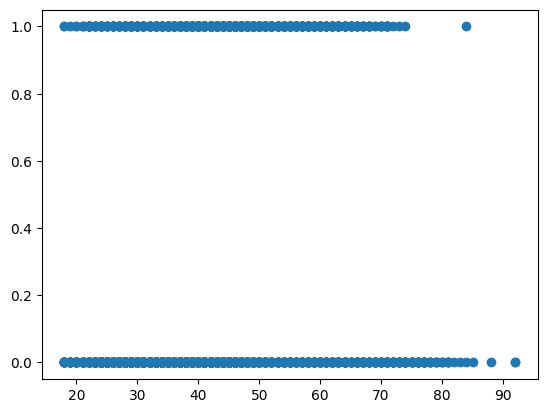

In [ ]:
import matplotlib.pyplot as plt
plt.scatter(data["Age"], data["Exited"])

/tmp/ipykernel_895/690491911.py:19: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  churn_by_age = data.groupby('Age_Group')['Exited'].mean()


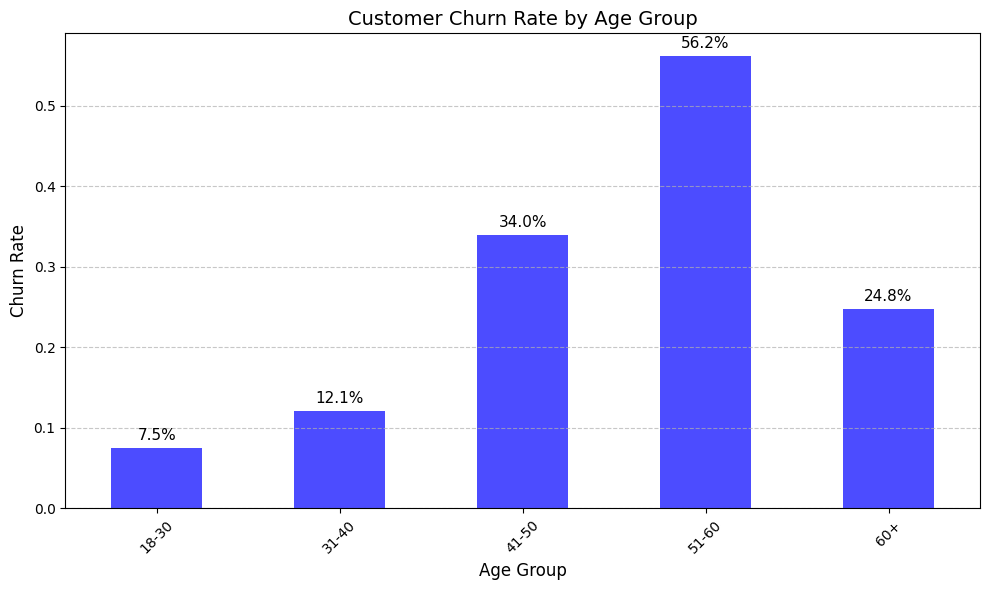

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

# Зареждане на данните директно тук, за да се избегне NameError при нова сесия
file_path = "https://raw.github.com/jan-source/ppa_erp_student/main/sessions/2_session/"
data_a = pd.read_csv(f"{file_path}churn_part_a.csv")
data_b = pd.read_csv(f"{file_path}churn_part_b.csv")
data = pd.merge(data_a, data_b, on="CustomerId", how="inner")
data = data.dropna(axis=0)

# Създаване на възрастови групи и анализ на оттока (churn)
data.loc[:, 'Age_Group'] = pd.cut(
        data['Age'],
        bins=[17, 30, 40, 50, 60, 100],
        labels=['18-30', '31-40', '41-50', '51-60', '60+']
        )

# Изчисляване на процента на отток за всяка възрастова група
churn_by_age = data.groupby('Age_Group')['Exited'].mean()

# Създаване на стълбовидна диаграма
plt.figure(figsize=(10, 6))
churn_by_age.plot(kind='bar', color='blue', alpha=0.7)
plt.title('Customer Churn Rate by Age Group', fontsize=14)
plt.xlabel('Age Group', fontsize=12)
plt.ylabel('Churn Rate', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Добавяне на етикети с проценти над всеки стълб
for i, value in enumerate(churn_by_age):
    plt.text(i, value + 0.01, f'{value:.1%}', ha='center', fontsize=11)

plt.tight_layout()
plt.show()

In [6]:
x = data[["Age","CreditScore","Balance"]]

In [7]:
y = data["Exited"]

In [9]:
from sklearn.linear_model import LogisticRegression

# Дефиниране на random_variable, ако не е изпълнена предишната клетка
random_variable = 1234

log_reg_simple = LogisticRegression(random_state=random_variable)

In [10]:
log_reg_simple.fit(x, y)

LogisticRegression(random_state=1234)

In [11]:
log_reg_simple.coef_

array([[ 6.33155132e-02, -7.71750832e-04,  5.02711176e-06]])

In [14]:
import numpy as np
import pandas as pd

coefficients_formated = pd.concat(
    [
     pd.Series(['Age', 'CreditScore', 'Balance']),
     pd.DataFrame(np.transpose(log_reg_simple.coef_))
    ],
     axis=1
 )

In [15]:
coefficients_formated

,0,0
0,Age,0.063316
1,CreditScore,-0.000772
2,Balance,0.000005


In [24]:
predictions = log_reg_simple.predict(x)

In [19]:
len(log_reg_simple.predict(x))

9996

In [18]:
sum(log_reg_simple.predict(x))

np.int64(411)

In [17]:
log_reg_simple.predict_proba(x)

array([[0.84242597, 0.15757403],
       [0.68642596, 0.31357404],
       [0.87303642, 0.12696358],
       ...,
       [0.89338001, 0.10661999],
       [0.80487652, 0.19512348],
       [0.8851447 , 0.1148553 ]])

In [26]:
from sklearn.metrics import confusion_matrix

confusion_matrix(y, predictions, labels=[True, False])

array([[ 125,  286],
       [1911, 7674]])

In [29]:
accuracy_score(y, predictions)

0.7802120848339336